In [1]:
import torch, torchvision
print(torch.__version__, torchvision.__version__)
print("GPU :", torch.cuda.is_available())

2.14.1+cpu 0.29.1+cpu
GPU : False


In [ ]:
from torchvision.datasets import EuroSAT

dataset = EuroSAT(root="data", download=True)
print(len(dataset))
print(dataset.classes)

100.0%


27000
['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']


: 

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

targets = np.array(dataset.targets)

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for classe, ax in enumerate(axes.flat):
    idx = np.where(targets == classe)[0][0]
    img, _ = dataset[idx]
    ax.imshow(img)
    ax.set_title(dataset.classes[classe], fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
pd.Series(targets).value_counts()

,count
0,3000
1,3000
2,3000
7,3000
9,3000
3,2500
6,2500
4,2500
8,2500
5,2000


In [ ]:
arr = np.array(img)
arr.shape, arr.dtype, arr.min(), arr.max()

((64, 64, 3), dtype('uint8'), np.uint8(21), np.uint8(80))

In [ ]:
for classe, nom in enumerate(dataset.classes):
    idxs = np.where(targets == classe)[0][:200]
    moyennes = [np.array(dataset[i][0]).mean(axis=(0, 1)) for i in idxs]
    r, g, b = np.mean(moyennes, axis=0)
    print(f"{nom:22s} R={r:5.1f}  G={g:5.1f}  B={b:5.1f}")

AnnualCrop             R=128.8  G=118.9  B=116.3
Forest                 R= 38.6  G= 63.6  B= 75.8
HerbaceousVegetation   R= 98.4  G= 98.7  B=103.8
Highway                R= 89.7  G= 97.6  B=103.7
Industrial             R=122.9  G=125.2  B=134.1
Pasture                R= 61.4  G= 87.4  B= 91.8
PermanentCrop          R=119.3  G=114.2  B=112.6
Residential            R= 99.5  G=103.4  B=112.5
River                  R= 66.3  G= 86.6  B= 97.1
SeaLake                R= 46.9  G= 71.7  B= 87.7


In [ ]:
X_img = np.stack([np.array(dataset[i][0]) for i in range(len(dataset))])
y = np.array(dataset.targets)
print(X_img.shape, X_img.dtype, y.shape)



(27000, 64, 64, 3) uint8 (27000,)


In [ ]:
mean_rgb = X_img.mean(axis=(1, 2))
std_rgb = X_img.std(axis=(1, 2))

gray = X_img.mean(axis=3, dtype=np.float32)
dx = np.abs(np.diff(gray, axis=2)).mean(axis=(1, 2))
dy = np.abs(np.diff(gray, axis=1)).mean(axis=(1, 2))
texture = np.column_stack([dx, dy])

print(mean_rgb.shape, std_rgb.shape, texture.shape)

(27000, 3) (27000, 3) (27000, 2)


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

def evaluer(features, nom):
    Xtr, Xte, ytr, yte = train_test_split(
        features, y, test_size=0.2, stratify=y, random_state=42)
    clf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
    clf.fit(Xtr, ytr)
    pred = clf.predict(Xte)
    print(f"{nom:32s} {features.shape[1]:2d} variables  précision = {accuracy_score(yte, pred):.3f}")
    return pred, yte

evaluer(mean_rgb, "Couleur moyenne")
evaluer(np.hstack([mean_rgb, std_rgb]), "+ écart-type")
pred, yte = evaluer(np.hstack([mean_rgb, std_rgb, texture]), "+ texture")

Couleur moyenne                   3 variables  précision = 0.603
+ écart-type                      6 variables  précision = 0.778
+ texture                         8 variables  précision = 0.825


In [ ]:
   import pandas as pd
   from sklearn.metrics import confusion_matrix

   cm = confusion_matrix(yte, pred)
   pd.DataFrame(cm, index=dataset.classes, columns=dataset.classes)

,AnnualCrop,Forest,HerbaceousVegetation,Highway,Industrial,Pasture,PermanentCrop,Residential,River,SeaLake
AnnualCrop,526,0,3,9,1,18,22,0,16,5
Forest,0,580,5,0,0,12,0,0,1,2
HerbaceousVegetation,2,2,438,19,17,10,74,16,22,0
Highway,33,0,24,243,30,21,50,27,72,0
Industrial,0,0,3,10,472,0,0,15,0,0
Pasture,4,5,18,9,0,351,4,0,9,0
PermanentCrop,19,0,46,32,7,17,361,6,12,0
Residential,0,0,4,11,9,0,2,574,0,0
River,26,6,6,80,14,19,10,1,336,2
SeaLake,7,2,1,1,0,2,0,0,12,575


In [ ]:
AH, BH = evaluer(np.hstack([mean_rgb, std_rgb]), "+ écart-type")
import pandas as pd
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(AH, BH)
pd.DataFrame(cm, index=dataset.classes, columns=dataset.classes)

+ écart-type                      6 variables  précision = 0.778


,AnnualCrop,Forest,HerbaceousVegetation,Highway,Industrial,Pasture,PermanentCrop,Residential,River,SeaLake
AnnualCrop,475,0,6,46,0,4,45,2,26,2
Forest,0,564,4,0,0,7,0,0,5,18
HerbaceousVegetation,18,4,429,26,0,14,60,10,6,9
Highway,19,2,13,202,13,9,32,27,73,3
Industrial,0,0,14,27,451,0,5,23,11,0
Pasture,19,21,9,20,0,353,16,0,19,3
PermanentCrop,44,0,62,44,0,5,313,8,9,0
Residential,2,0,36,70,34,0,11,526,6,0
River,19,2,22,65,2,8,18,4,339,16
SeaLake,4,7,5,0,0,0,0,0,6,549


In [ ]:
def evaluer_multi(features, nom, n_repetitions=5):
    scores = []
    for seed in range(n_repetitions):
        Xtr, Xte, ytr, yte = train_test_split(
            features, y, test_size=0.2, stratify=y, random_state=seed)
        clf = RandomForestClassifier(n_estimators=200, random_state=seed, n_jobs=-1)
        clf.fit(Xtr, ytr)
        scores.append(accuracy_score(yte, clf.predict(Xte)))
    print(f"{nom:20s} {np.mean(scores):.3f} ± {np.std(scores):.3f}")

evaluer_multi(mean_rgb, "Couleur moyenne")
evaluer_multi(np.hstack([mean_rgb, std_rgb]), "+ écart-type")
evaluer_multi(np.hstack([mean_rgb, std_rgb, texture]), "+ texture")

Couleur moyenne      0.605 ± 0.005
+ écart-type         0.774 ± 0.006
+ texture            0.823 ± 0.005


In [ ]:
X_flat = X_img.reshape(len(X_img), -1).astype(np.float32) / 255
print(X_flat.shape)

Xtr, Xte, ytr, yte = train_test_split(
    X_flat, y, test_size=0.2, stratify=y, random_state=42)

clf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
clf.fit(Xtr, ytr)
print(f"Pixels bruts : {accuracy_score(yte, clf.predict(Xte)):.3f}")

(27000, 12288)
Pixels bruts : 0.675


In [ ]:
from sklearn.neighbors import NearestCentroid
from sklearn.preprocessing import StandardScaler

feats = np.hstack([mean_rgb, std_rgb, texture])
Xtr, Xte, ytr, yte = train_test_split(
    feats, y, test_size=0.2, stratify=y, random_state=42)

scaler = StandardScaler().fit(Xtr)
nc = NearestCentroid().fit(scaler.transform(Xtr), ytr)
print(f"Plus proche centroïde : {accuracy_score(yte, nc.predict(scaler.transform(Xte))):.3f}")

Plus proche centroïde : 0.489


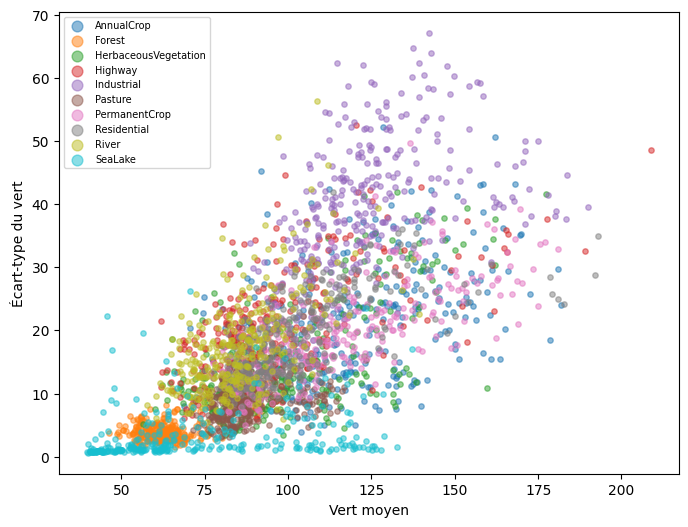

In [ ]:
fig, ax = plt.subplots(figsize=(8, 6))
for classe, nom in enumerate(dataset.classes):
    idx = np.where(y == classe)[0][:300]
    ax.scatter(mean_rgb[idx, 1], std_rgb[idx, 1], s=15, alpha=0.5, label=nom)
ax.set_xlabel("Vert moyen")
ax.set_ylabel("Écart-type du vert")
ax.legend(fontsize=7, markerscale=2)
plt.show()

In [ ]:
import torch

x = torch.tensor([[1., 2., 3.],
                  [4., 5., 6.]])
print(x.shape, x.dtype)
print(x.mean(dim=0))
print(x.mean(dim=1))

torch.Size([2, 3]) torch.float32
tensor([2.5000, 3.5000, 4.5000])
tensor([2., 5.])


In [ ]:
from torchvision import transforms

to_tensor = transforms.ToTensor()
img, label = dataset[0]
t = to_tensor(img)
print(t.shape, t.dtype, t.min(), t.max())

torch.Size([3, 64, 64]) torch.float32 tensor(0.3216) tensor(0.8000)


In [ ]:
from torchvision.datasets import EuroSAT
from torch.utils.data import DataLoader

dataset_t = EuroSAT(root="data", download=True, transform=transforms.ToTensor())

x1, y1 = dataset_t[0]
print(x1.shape, y1)

loader = DataLoader(dataset_t, batch_size=64, shuffle=True)
xb, yb = next(iter(loader))
print(xb.shape, yb.shape)
print(len(loader))

torch.Size([3, 64, 64]) 0
torch.Size([64, 3, 64, 64]) torch.Size([64])
422


In [1]:
for melange in [False, True]:
    loader = DataLoader(dataset_t, batch_size=64, shuffle=melange)
    _, yb = next(iter(loader))
    print(f"shuffle={melange} :", yb[:20].tolist())

NameError: name 'DataLoader' is not defined